# Attention mechanisms

We explore a bunch of mechanisms, which are built on top of each other.

# A simple self-attention mechanism without trainable weights

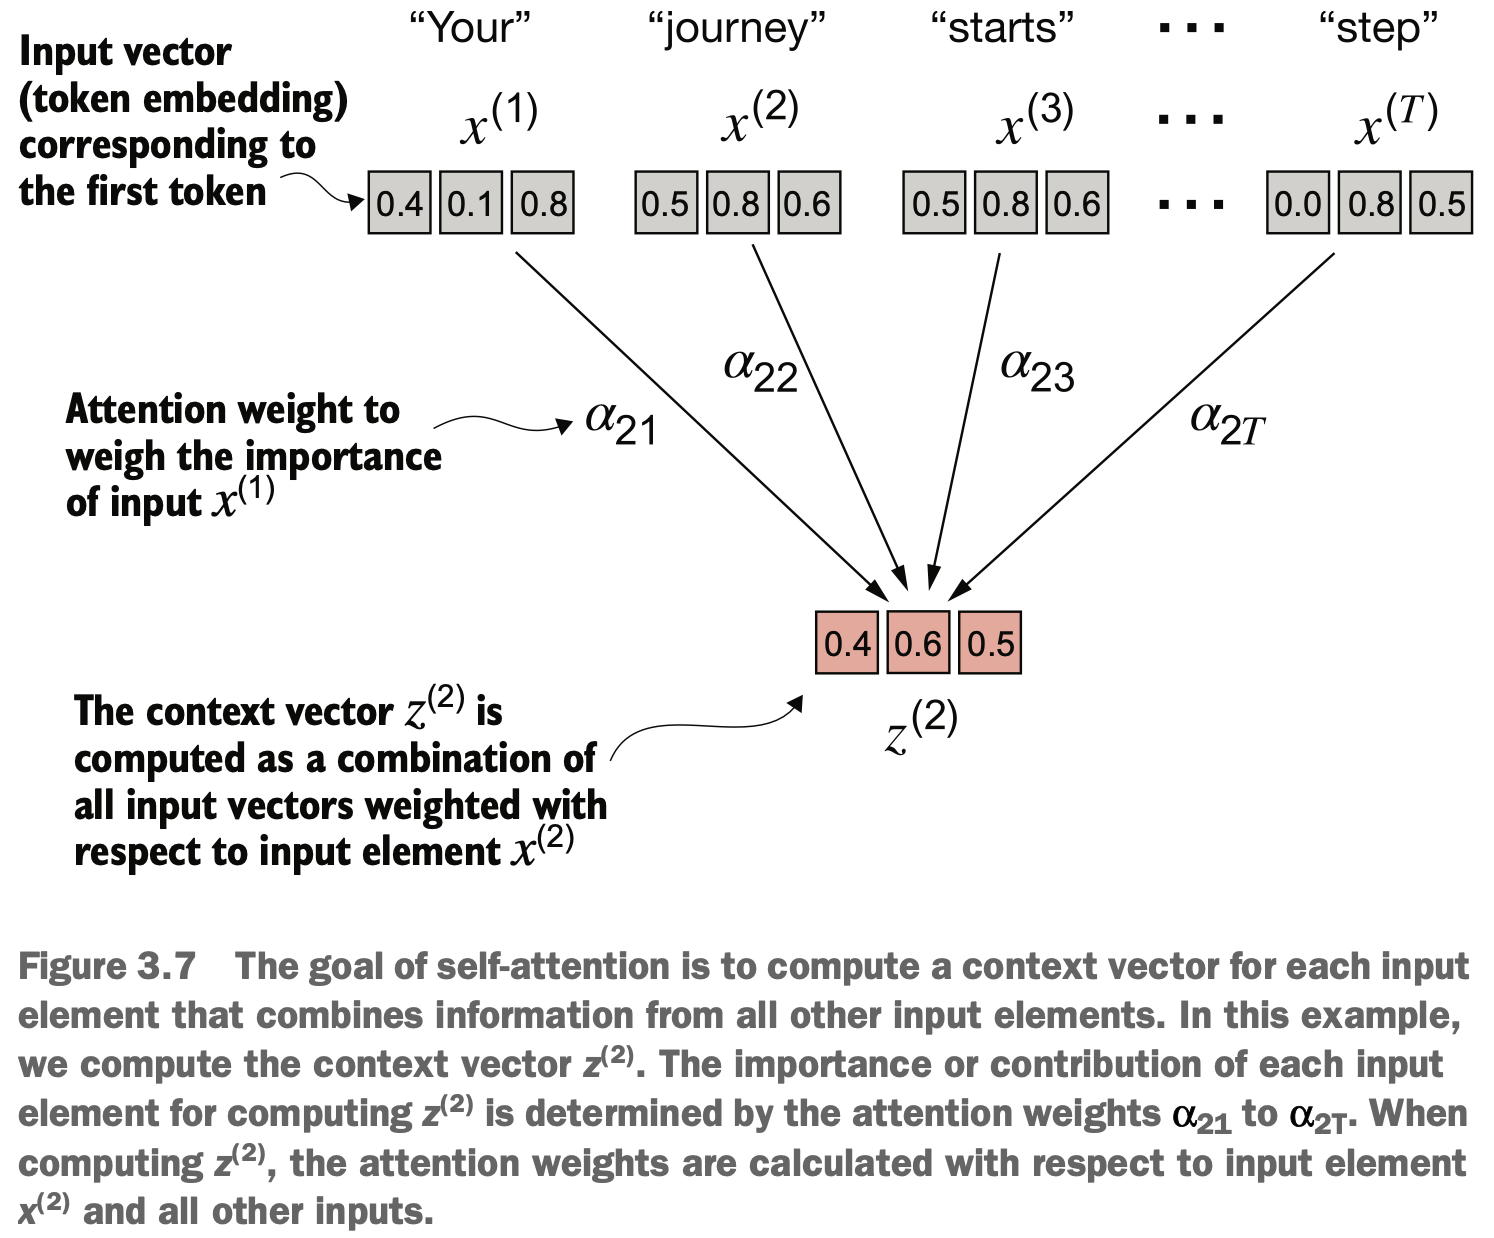

Each context vector can be thought of as an enriched vector representation of the original embedding vector. The enhanced embedding vector has information about its corresponding token as well as all other input elements.

$$
z^{(2)} = f\left(x^{(1)}, x^{(2)}, \ldots, x^{(T)}\right)
$$

Now we see how to implement a simplified attention mechanism.

In [ ]:
from importlib.metadata import version
import tiktoken
import torch

tokenizer = tiktoken.get_encoding("gpt2")
text = ("Your journey starts with one step")
integers = tokenizer.encode(text)
input_ids = torch.tensor(integers)
vocab_size = 6
output_dim = 3
torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
print(embedding_layer.weight)

In [ ]:
import torch
inputs = torch.tensor(
[[0.43, 0.15, 0.89],
[0.55, 0.87, 0.66],
[0.57, 0.85, 0.64],
[0.22, 0.58, 0.33],
[0.77, 0.25, 0.10],
[0.05, 0.80, 0.55]]
)

First we need to calculate the attention scores $\omega$, which tells us how important each part of the sentence is compared to our query token.

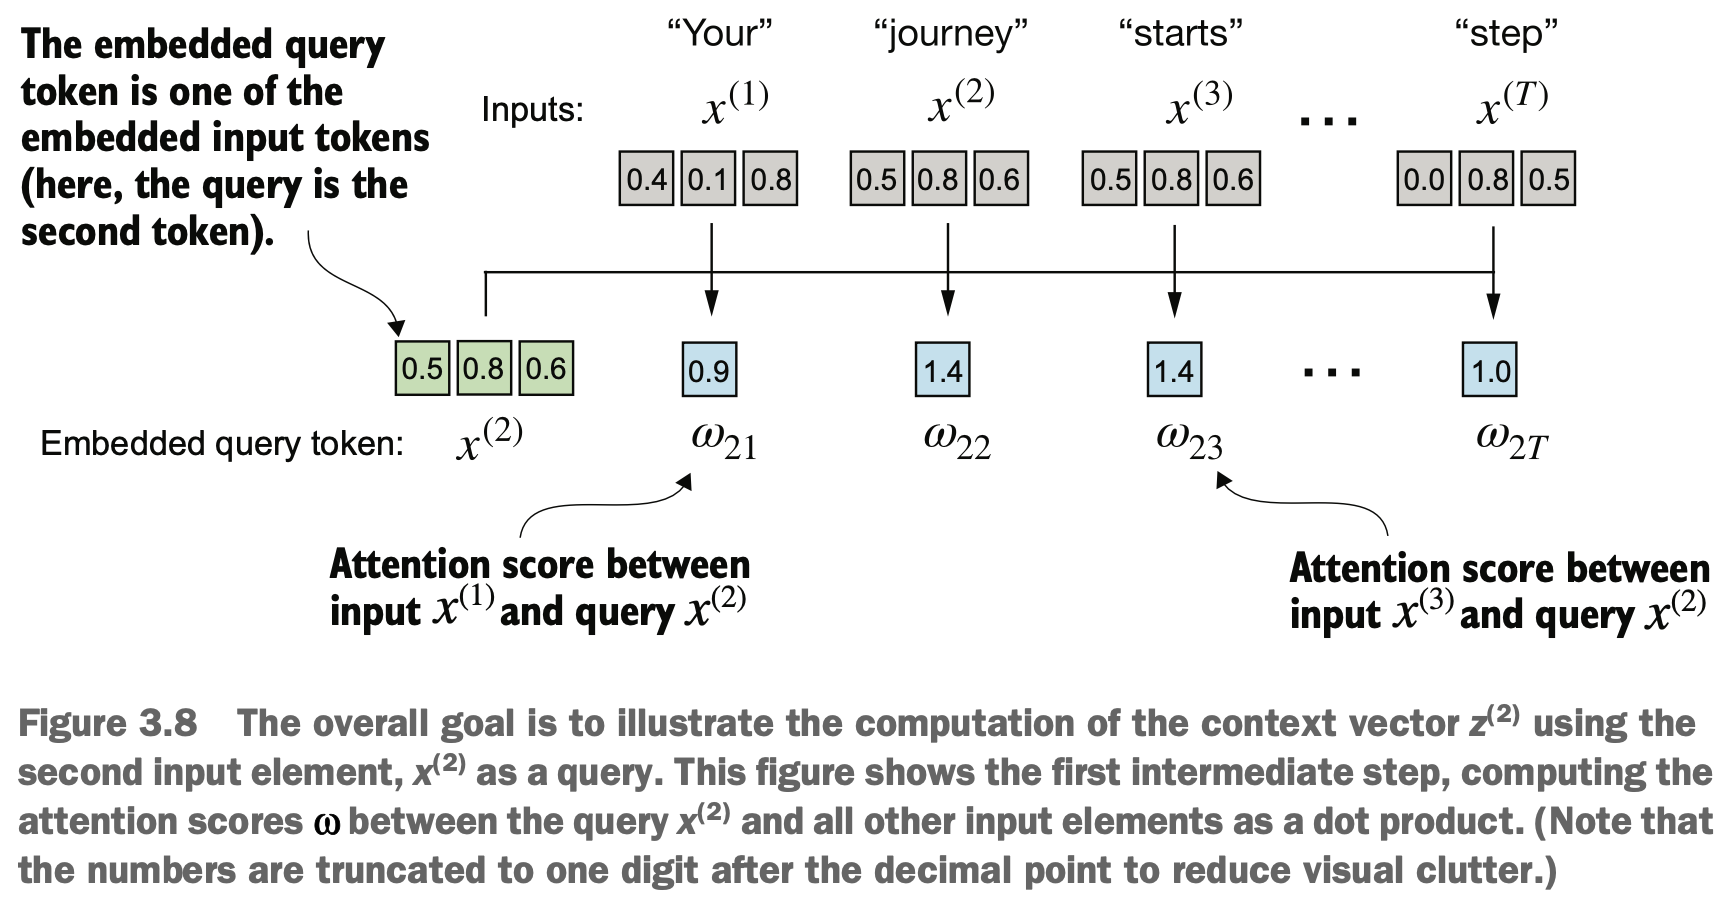

We calculate the attention scores between the query token $x^{(2)}$ and other input tokens using a dot product.

In [ ]:
query = inputs[1]
attention_scores_2 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
    attention_scores_2[i] = torch.dot(x_i, query)
print(attention_scores_2)

Next we normalise the attention scores to obtain attention weights.

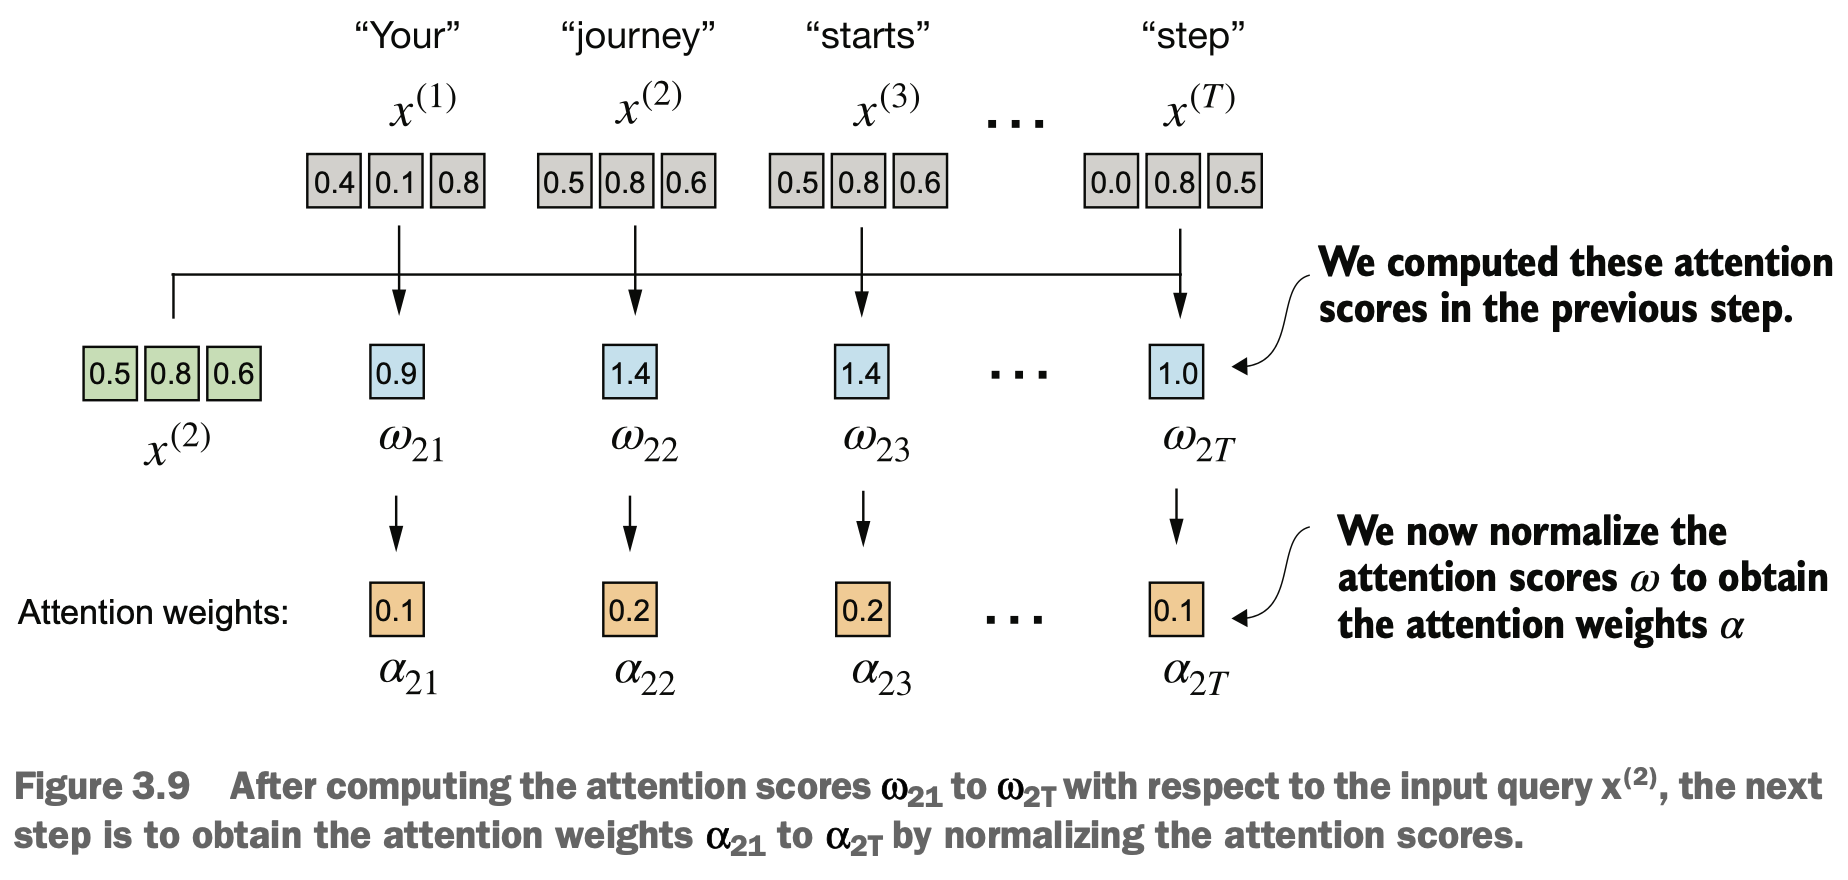

In [ ]:
attention_weights_2_tmp = attention_scores_2/attention_scores_2.sum()
print("Attention weights:", attention_weights_2_tmp)
print("Sum: ", attention_weights_2_tmp.sum())

In practice, instead of doing the summation for normalization, we use the $\text{softmax(x) = } e^{x}$ which is better at handling extreme values and offers better gradients during backpropagation. The earlier approach can lead to negative attention weights which is difficult to interpret. Softmax on the other hand always produces positive weights, which could be interpreted as probabilities or relative importance.

In [ ]:
def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)

attention_weights_2_naive = softmax_naive(attention_scores_2)
print("Attention weights:", attention_weights_2_naive)
print("Sum: ", attention_weights_2_naive.sum())

Our naive implementation is not suitable as it might suffer from overflow or underflow when dealing with extremely large or small inputs. So it is better to use the Pytorch implementation which is an optimized version.

Now we have the normalized attention weights and we will compute the context vector $z^{2}$:

In [ ]:
attention_weights_2 = torch.softmax(attention_scores_2, dim=0)
print("Attention weights:", attention_weights_2)
print("Sum:", attention_weights_2.sum())

query = inputs[1]
context_vec_2 = torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
    context_vec_2 += attention_weights_2[i]*x_i
print(context_vec_2)

# Computing attention weights for all input tokens

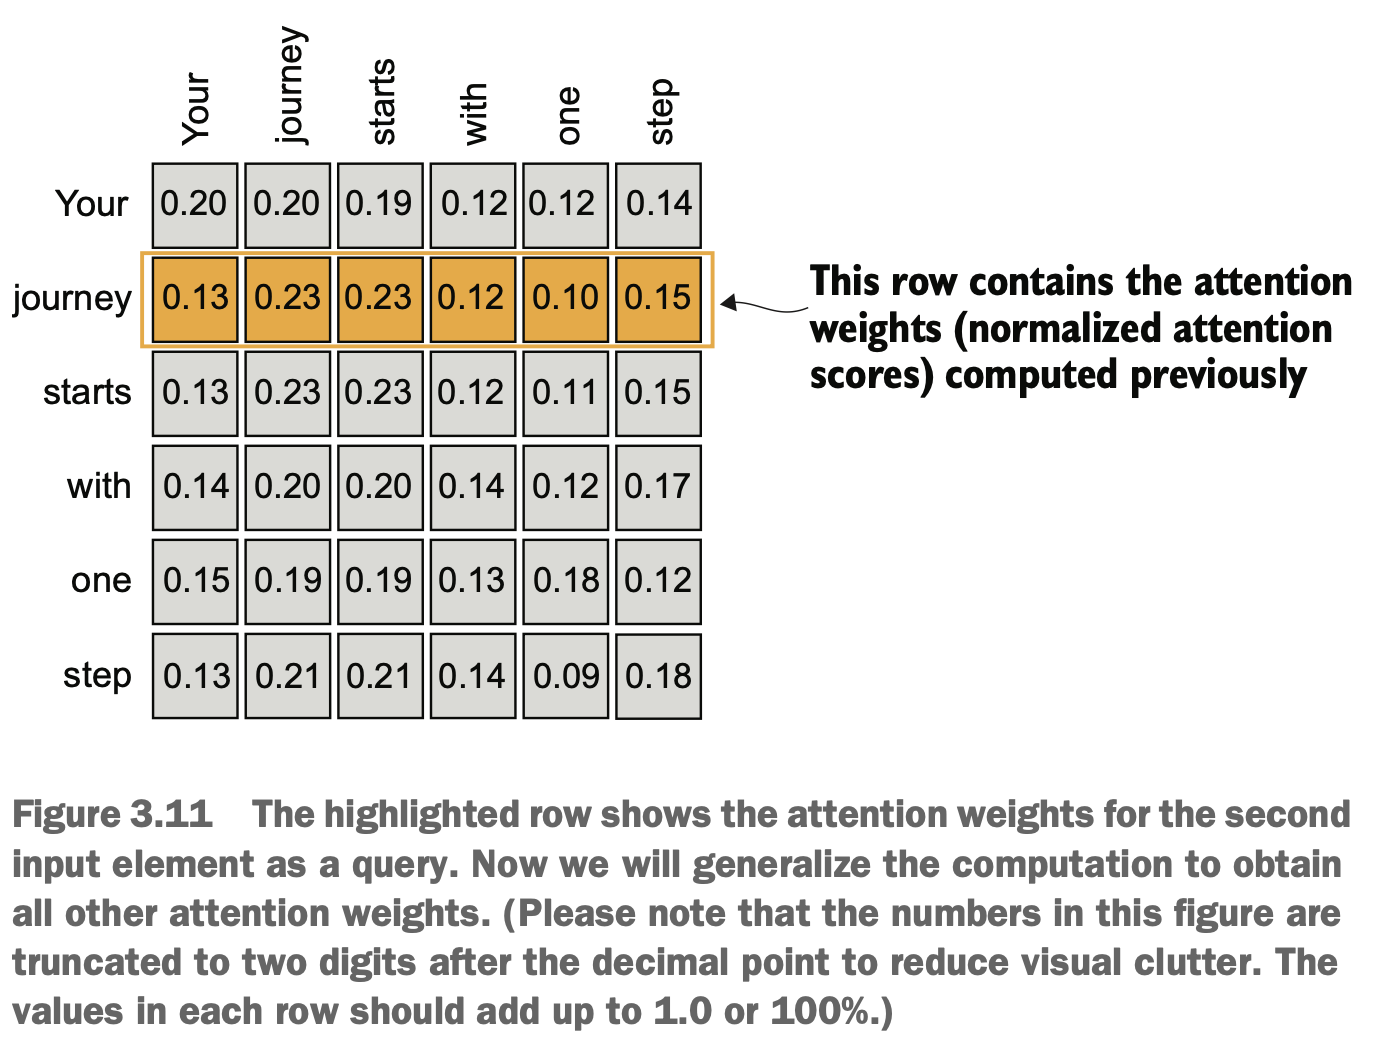

We compute the attention weights for each input token at the same time.

In [ ]:
attention_scores = torch.empty(6,6)
for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attention_scores[i,j] = torch.dot(x_i, x_j)
print(attention_scores)

# using matrix multiplication which is faster
attention_scores = inputs @ inputs.T
print(attention_scores)

In [ ]:
# normalizing the attention scores along each row
attention_weights = torch.softmax(attention_scores, dim=-1)
print(attention_weights)

In [ ]:
# now we compute the context vectors
all_context_vectors = attention_weights @ inputs
print(all_context_vectors)

# Implementing self-attention with trainable weights
In the last section we implemented self-attention with fixed weights, now we make the weights trainable as well. This self-attention mechanism is called scaled dot-product attention. We introduce learnable weight matrices which will be used to produce context vectors.

## Computing the attention weights step by step
We introduce three weight matrices: $W_{q}, W_{k}, W_{v}$ which will be used to project the embedded input tokens, $x^{(i)}$ into query, key and value vectors as shown below:

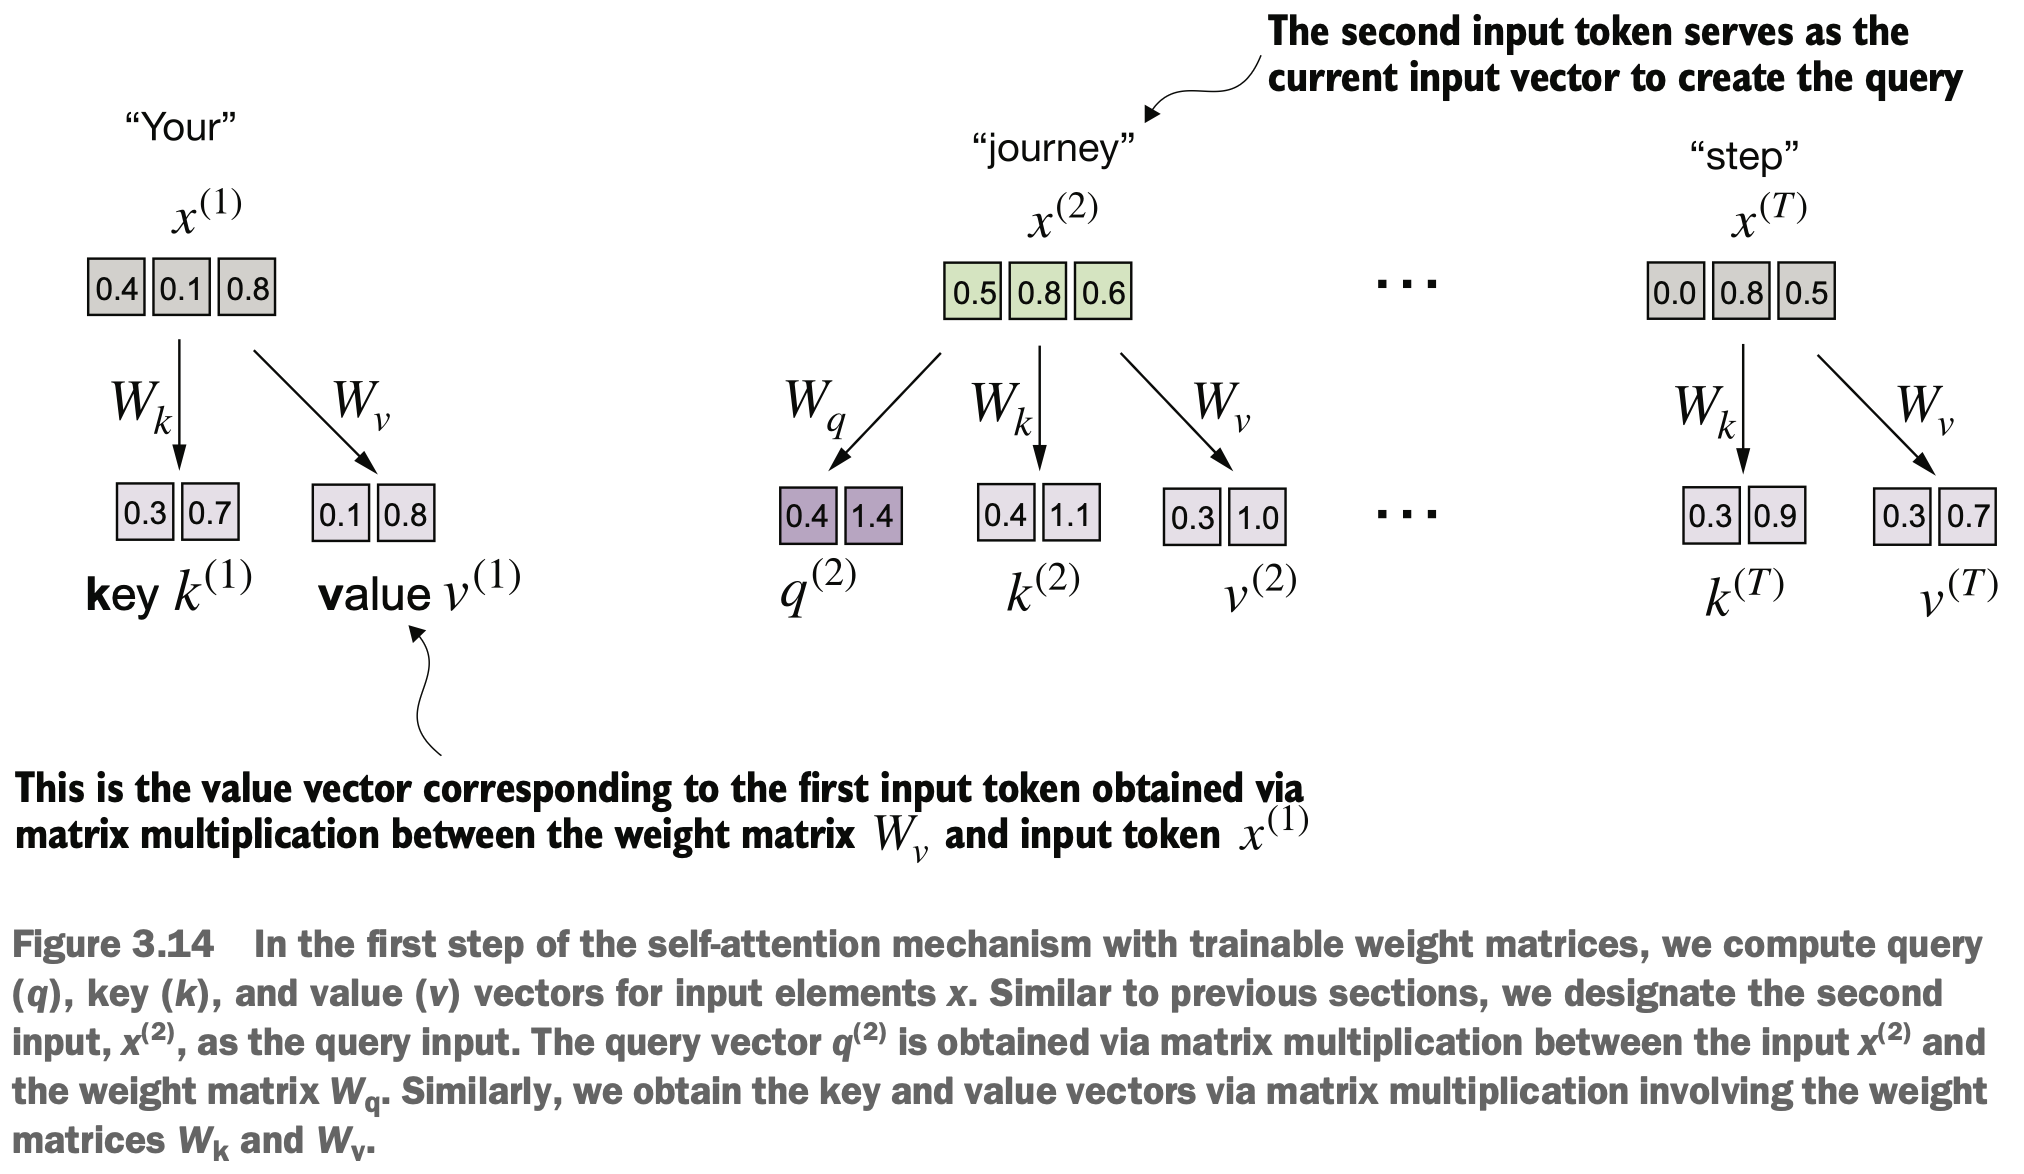

In [ ]:
# calculating one context vector
x_2 = inputs[1]
d_in = inputs.shape[1]
d_out = 2

# initialize weight matrices
torch.manual_seed(123)
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

# compute q,k,v vectors
query_2 = x_2 @ W_query
key_2 = x_2 @ W_key
value_2 = x_2 @ W_value
print(query_2)

# getting the keys and values for all token
keys = inputs @ W_key
values = inputs @ W_value
print("keys.shape: ", keys.shape)
print("values.shape: ", values.shape)

Now we calculate the attention scores

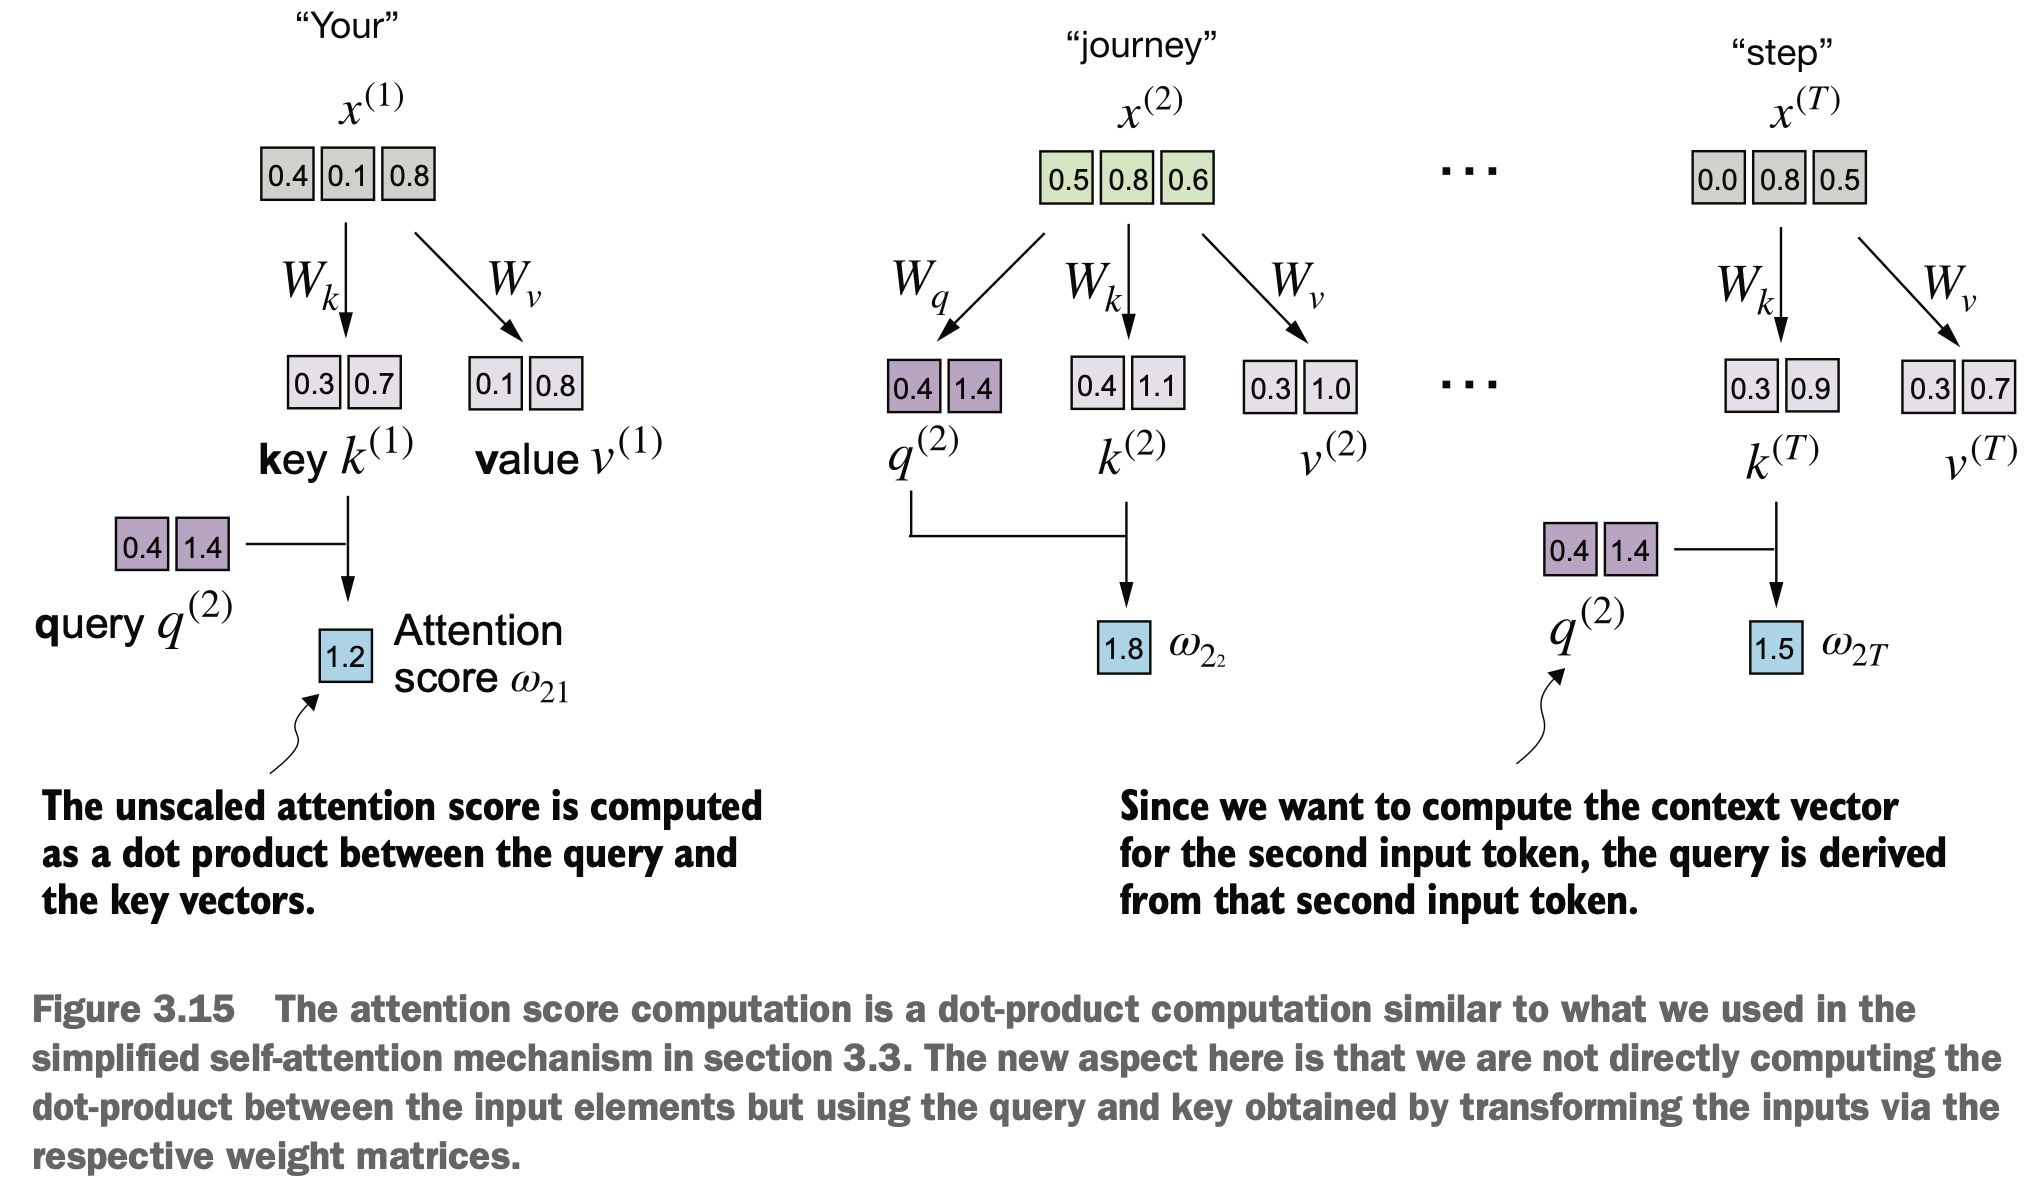

In [ ]:
# attention score w22
keys_2 = keys[1]
attention_score_22 = query_2.dot(keys_2)
print(attention_score_22)

# calculating all attention scores
attention_score_2 = query_2 @ keys.T
print(attention_score_2)

Now we convert the attention scores to attention weights

In [ ]:
d_k = keys.shape[-1]
attention_weights_2 = torch.softmax(attention_score_2 / d_k**0.5, dim = -1)
print(attention_weights_2)

# now we calculate the context vectors as the weighted sum of value vectors
context_vec_2 = attention_weights_2 @ values
print(context_vec_2)

We computed the context vector for one token. Now we will generalize this for all the tokens in the input sequence.

In [ ]:
# a compace self-attention class
import torch.nn as nn
class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self,x):
        queries = x @ self.W_query
        keys = x @ self.W_key
        values = x @ self.W_value
        attention_scores = queries @ keys.T
        attention_weights = torch.softmax(attention_scores / keys.shape[-1]**0.5, dim=-1)
        context_vector = attention_weights @ values
        return context_vector

In [ ]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
print(sa_v1(inputs))

In [57]:
# same self-attention class using nn.Linear
import torch.nn as nn
class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias = False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias = qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias = qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias = qkv_bias)

    def forward(self,x):
        queries = self.W_query(x)
        keys = self.W_key(x)
        values = self.W_value(x)
        attention_scores = queries @ keys.T
        attention_weights = torch.softmax(attention_scores / keys.shape[-1]**0.5, dim=-1)
        context_vector = attention_weights @ values
        return context_vector

torch.manual_seed(789)
sa_v2 = SelfAttention_v2(d_in, d_out)
print(sa_v2(inputs))

tensor([[-0.0739,  0.0713],
        [-0.0748,  0.0703],
        [-0.0749,  0.0702],
        [-0.0760,  0.0685],
        [-0.0763,  0.0679],
        [-0.0754,  0.0693]], grad_fn=<MmBackward0>)


Next 